## Câu 1 : Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính

In [1]:
import pandas as pd

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1 - Bài 2 - Câu 1")

df = pd.read_csv("data/titanic.csv")

print("\n1. Kích thước dữ liệu")
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\n2. Năm dòng dữ liệu đầu tiên")
print(df.head())

print("\n3. Thông tin các thuộc tính")
df.info()

print("\n4. Thống kê mô tả")
print(df.describe(include="all"))


Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1 - Bài 2 - Câu 1

1. Kích thước dữ liệu
Số dòng: 1309
Số cột: 14

2. Năm dòng dữ liệu đầu tiên
   pclass  survived                                             name     sex  \
0       1         1                    Allen, Miss. Elisabeth Walton  female   
1       1         1                   Allison, Master. Hudson Trevor    male   
2       1         0                     Allison, Miss. Helen Loraine  female   
3       1         0             Allison, Mr. Hudson Joshua Creighton    male   
4       1         0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   

## Câu 2: Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất.

In [2]:
import pandas as pd

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1 - Bài 2 - Câu 2")

df = pd.read_csv("data/titanic.csv")

so_luong_rong = df.isnull().sum()

top_5 = so_luong_rong.sort_values(ascending=False).head(5)

print("\n5 thuộc tính có số lượng giá trị rỗng nhiều nhất")
print(top_5)

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1 - Bài 2 - Câu 2

5 thuộc tính có số lượng giá trị rỗng nhiều nhất
body         1188
cabin        1014
boat          823
home.dest     564
age           263
dtype: int64


## Câu 3: Vẽ biểu đồ khảo sát sự liên quan giữa thuộc tính Độ tuổi (age), Giới tính (sex) và thuộc tính quyết định – khả năng sống sót (survived) và đưa ra nhận xét.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 3


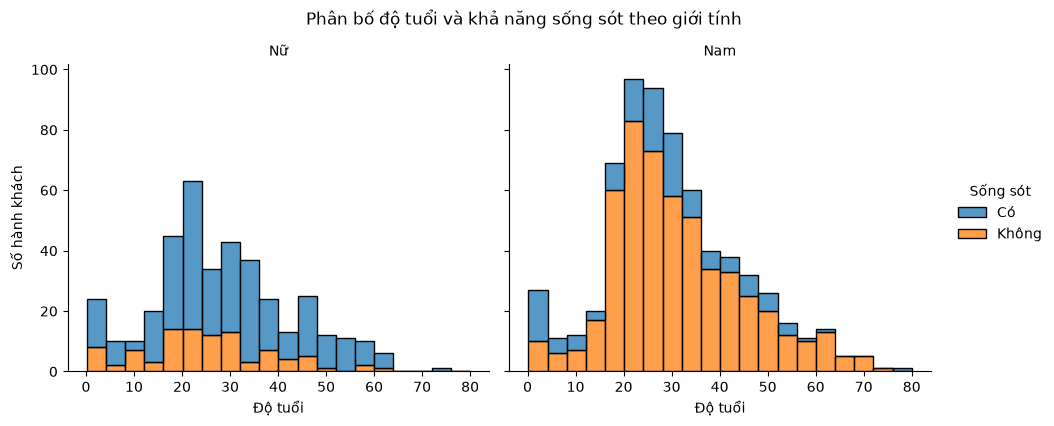


Tỷ lệ sống sót theo giới tính
sex
female    72.75
male      19.10
Name: survived, dtype: float64


In [3]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 3")

df = pd.read_csv("data/titanic.csv")

du_lieu = df.dropna(subset=["age"]).copy()

du_lieu["Giới tính"] = du_lieu["sex"].map({
    "male": "Nam",
    "female": "Nữ"
})

du_lieu["Sống sót"] = du_lieu["survived"].map({
    0: "Không",
    1: "Có"
})

bieu_do = sns.displot(
    data=du_lieu,
    x="age",
    hue="Sống sót",
    col="Giới tính",
    bins=20,
    multiple="stack",
    height=4,
    aspect=1.2
)

bieu_do.set_axis_labels("Độ tuổi", "Số hành khách")
bieu_do.set_titles("{col_name}")
bieu_do.figure.suptitle(
    "Phân bố độ tuổi và khả năng sống sót theo giới tính",
    y=1.05
)

plt.show()

ty_le = df.groupby("sex")["survived"].mean() * 100

print("\nTỷ lệ sống sót theo giới tính")
print(ty_le.round(2))


- Nhận xét : Qua biểu đồ, hành khách nữ có tỷ lệ sống sót cao hơn so với nam. Phần lớn hành khách nam không sống sót tập trung ở độ tuổi 20–40. Giới tính có mối liên hệ rõ rệt với khả năng sống sót, trong khi độ tuổi cũng có sự ảnh hưởng nhất định

## Câu 4: Vẽ biểu đồ khảo sát sự liên quan giữa thuộc tính Cổng lên tàu (embarked) và loại vé (pclass) với khả năng sống sót (survived), phân biệt theo Giới tính (sex) và đưa ra nhận xét.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 4


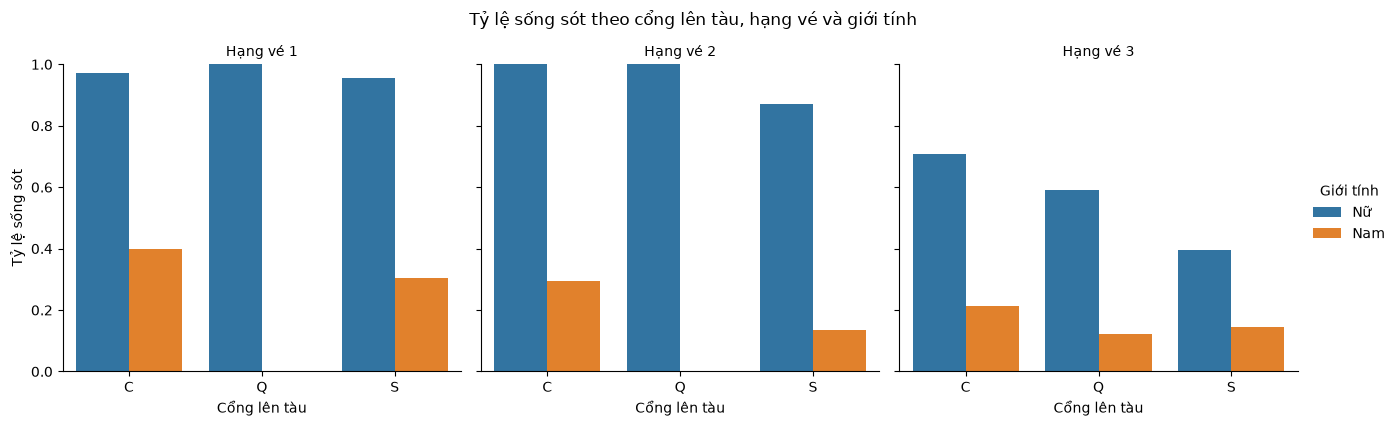


Tỷ lệ sống sót theo từng nhóm (%)
pclass  embarked  Giới tính
1       C         Nam           40.00
                  Nữ            97.18
        Q         Nam            0.00
                  Nữ           100.00
        S         Nam           30.56
                  Nữ            95.65
2       C         Nam           29.41
                  Nữ           100.00
        Q         Nam            0.00
                  Nữ           100.00
        S         Nam           13.42
                  Nữ            87.10
3       C         Nam           21.43
                  Nữ            70.97
        Q         Nam           12.28
                  Nữ            58.93
        S         Nam           14.48
                  Nữ            39.53
Name: survived, dtype: float64


In [4]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 4")

du_lieu_cau4 = df.dropna(subset=["embarked"]).copy()

du_lieu_cau4["Giới tính"] = du_lieu_cau4["sex"].map({
    "male": "Nam",
    "female": "Nữ"
})

bieu_do = sns.catplot(
    data=du_lieu_cau4,
    x="embarked",
    y="survived",
    hue="Giới tính",
    col="pclass",
    kind="bar",
    order=["C", "Q", "S"],
    hue_order=["Nữ", "Nam"],
    errorbar=None,
    height=4,
    aspect=1.1
)

bieu_do.set_axis_labels("Cổng lên tàu", "Tỷ lệ sống sót")
bieu_do.set_titles("Hạng vé {col_name}")
bieu_do.set(ylim=(0, 1))

bieu_do.figure.suptitle(
    "Tỷ lệ sống sót theo cổng lên tàu, hạng vé và giới tính",
    y=1.05
)

plt.show()

ty_le = du_lieu_cau4.groupby(
    ["pclass", "embarked", "Giới tính"]
)["survived"].mean() * 100

print("\nTỷ lệ sống sót theo từng nhóm (%)")
print(ty_le.round(2))


- Nhận xét: Qua biểu đồ, hành khách nữ có tỷ lệ sống sót cao hơn nam ở tất cả các nhóm hạng vé và cổng lên tàu. Hành khách hạng vé 1 và 2 nhìn chung có tỷ lệ sống sót cao hơn hạng vé 3.

## Câu 5: Thống kê số người đi cùng (anh chị em/vợ chồng hoặc cha mẹ/con cái) và khảo sát sự liên quan với thuộc tính quyết định và đưa ra nhận xét.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 5

Thống kê số người đi cùng và khả năng sống sót
 so_nguoi_di_cung  so_hanh_khach  so_nguoi_song_sot  ty_le_song_sot
                0            790                239           30.25
                1            235                126           53.62
                2            159                 90           56.60
                3             43                 30           69.77
                4             22                  6           27.27
                5             25                  5           20.00
                6             16                  4           25.00
                7              8                  0            0.00
               10             11                  0            0.00


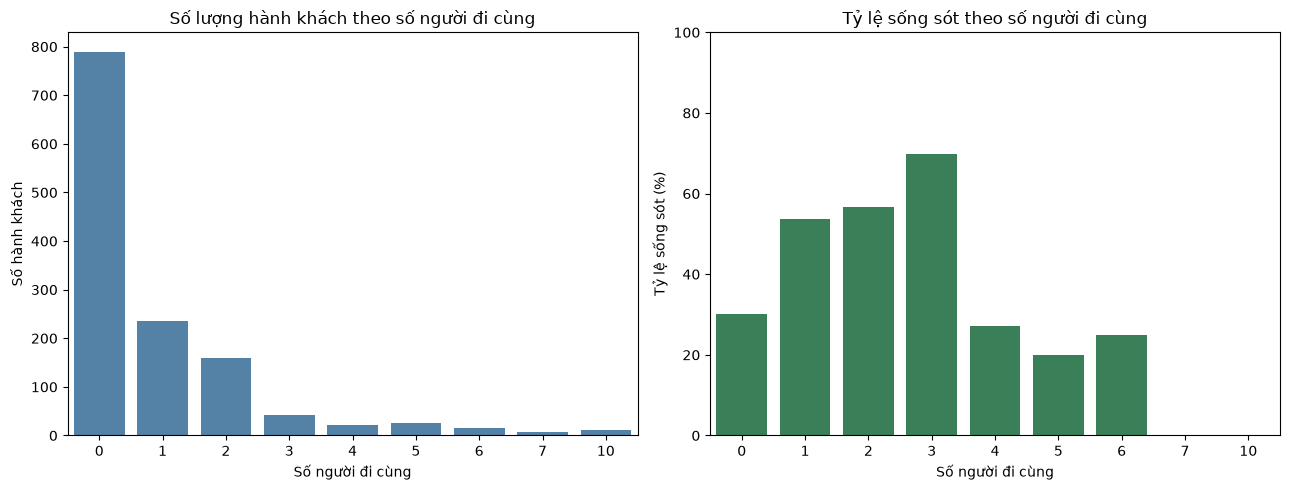

In [5]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 5")

# Tạo thuộc tính số người đi cùng
du_lieu_cau5 = df.copy()
du_lieu_cau5["so_nguoi_di_cung"] = (
    du_lieu_cau5["sibsp"] + du_lieu_cau5["parch"]
)

# Thống kê số hành khách và tỷ lệ sống sót
thong_ke = du_lieu_cau5.groupby("so_nguoi_di_cung")["survived"].agg(
    so_hanh_khach="count",
    so_nguoi_song_sot="sum",
    ty_le_song_sot="mean"
).reset_index()

thong_ke["ty_le_song_sot"] = (
    thong_ke["ty_le_song_sot"] * 100
).round(2)

print("\nThống kê số người đi cùng và khả năng sống sót")
print(thong_ke.to_string(index=False))

# Vẽ biểu đồ khảo sát
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=thong_ke,
    x="so_nguoi_di_cung",
    y="so_hanh_khach",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Số lượng hành khách theo số người đi cùng")
axes[0].set_xlabel("Số người đi cùng")
axes[0].set_ylabel("Số hành khách")

sns.barplot(
    data=thong_ke,
    x="so_nguoi_di_cung",
    y="ty_le_song_sot",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Tỷ lệ sống sót theo số người đi cùng")
axes[1].set_xlabel("Số người đi cùng")
axes[1].set_ylabel("Tỷ lệ sống sót (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

- Nhận xét: Qua biểu đồ, hành khách đi cùng từ 1 đến 3 người có tỷ lệ sống sót cao hơn so với người đi một mình. Trong đó, nhóm đi cùng 3 người có tỷ lệ sống sót cao nhất, đạt 69,77%. Những nhóm đi cùng nhiều người hơn có tỷ lệ sống sót thấp. 

## Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết.

In [ ]:

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 6")

du_lieu_cau6 = df.copy()

print("\nSố lượng giá trị thiếu trước khi xử lý")
print(du_lieu_cau6.isnull().sum())

cot_can_xoa = ["boat", "body", "cabin", "home.dest", "ticket"]
du_lieu_cau6 = du_lieu_cau6.drop(columns=cot_can_xoa)

du_lieu_cau6["age"] = du_lieu_cau6["age"].fillna(
    du_lieu_cau6["age"].median()
)

du_lieu_cau6["fare"] = du_lieu_cau6["fare"].fillna(
    du_lieu_cau6["fare"].median()
)

du_lieu_cau6["embarked"] = du_lieu_cau6["embarked"].fillna(
    du_lieu_cau6["embarked"].mode()[0]
)

print("\nSố lượng giá trị thiếu sau khi xử lý")
print(du_lieu_cau6.isnull().sum())

print("\nKích thước dữ liệu sau khi xử lý")
print("Số dòng:", du_lieu_cau6.shape[0])
print("Số cột:", du_lieu_cau6.shape[1])

print("\nNăm dòng dữ liệu sau khi xử lý")
print(du_lieu_cau6.head())


Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 6

Số lượng giá trị thiếu trước khi xử lý
pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

Số lượng giá trị thiếu sau khi xử lý
pclass      0
survived    0
name        0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Kích thước dữ liệu sau khi xử lý
Số dòng: 1309
Số cột: 9

Năm dòng dữ liệu sau khi xử lý
   pclass  survived                                             name     sex  \
0       1         1                    Allen, Miss. Elisabeth Walton  female   
1       1         1                   Allison, Master. Hudson Trevor    male   
2       1         0                     Allison, Miss. Helen Loraine  female   
3       1         0             Allison, Mr. Hud